# Regression Analysis of Jack Draper's performance metrics

**Author:** Galiya Galimova | Tennis Analyst

**Period:** 2018–2025  

**Data:** 2018-2025 ATP Tour matches (source: Jeff Sackmann's tennis_atp [github](https://github.com/JeffSackmann/tennis_atp))

---

### Executive Summary

**Objective:** Identify which serve and return performance metrics are statistically associated with winning a match.

**Method:** Logistic regression (an explanatory model)

**Metrics:**
- Serve: 1st serve percentage, 1st serve points won percentage, 2nd serve points won percentage
- Return: return points percentage
- Surface: Hard, Clay, Grass

**Key Insights:**
- First serve points won and second serve points won are the strongest positive predictors of winning (p < 0.001); aces and double faults are not statistically significant on their own. Adding return performance (rp_pct) more than doubles the model's explanatory power (pseudo-R² 0.35 → 0.64), showing that Draper's return game explains match outcomes more than his serve alone.
- Improving return points won by just 1 percentage point boosts Draper's win chance by 2.72 percentage points, improving first serve points won by 1 percentage point adds about 1.17 percentage points, and improving second serve points won by 1 percentage point adds about 0.75 percentage points. Aces and double faults barely matter for the final result once these percentages are accounted for.
- Against TOP 10 opponents, Draper's drop-off is concentrated in point conversion, not first serve accuracy. First-serve points won falls from 79% (wins) to 65% (losses), while first serve in percentage barely changes (59% vs 57%).

### Import the data

In [1]:
#Import libraries
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [2]:
#Display all columns
pd.set_option('display.max_columns', None)

In [3]:
#Import the ATP data from 2018 to 2025
atp_2018 = pd.read_csv('atp_matches_2018.csv')
atp_2019 = pd.read_csv('atp_matches_2019.csv')
atp_2020 = pd.read_csv('atp_matches_2020.csv')
atp_2021 = pd.read_csv('atp_matches_2021.csv')
atp_2022 = pd.read_csv('atp_matches_2022.csv')
atp_2023 = pd.read_csv('atp_matches_2023.csv')
atp_2024 = pd.read_csv('atp_matches_2024.csv')
atp_2025 = pd.read_csv('atp_matches_2025.csv')

In [4]:
#Keep the required columns in the dataset "atp_2025"
atp_2025 = atp_2025[['tourney_id', 'tourney_name', 'surface', 'draw_size', 'tourney_level', 'tourney_date', \
                     'match_num', 'winner_id', 'winner_seed', 'winner_entry', 'winner_name', 'winner_hand', \
                     'winner_ht', 'winner_ioc', 'winner_age', 'loser_id', 'loser_seed', 'loser_entry', 'loser_name', \
                     'loser_hand', 'loser_ht', 'loser_ioc', 'loser_age', 'score', 'best_of', 'round', 'minutes', \
                     'w_ace', 'w_df', 'w_svpt', 'w_1stIn', 'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', \
                     'w_bpFaced', 'l_ace', 'l_df', 'l_svpt', 'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', \
                     'l_bpSaved', 'l_bpFaced', 'winner_rank', 'winner_rank_points', 'loser_rank', 'loser_rank_points']]

In [5]:
#Combine all datasets into one dataset
atp = pd.concat([atp_2018, atp_2019, atp_2020, atp_2021, atp_2022, atp_2023, atp_2024, atp_2025])
atp.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
0,2018-M020,Brisbane,Hard,32.0,A,20180101,271.0,105992,NaN,NaN,Ryan Harrison,R,185.0,USA,25.6,104919,NaN,NaN,Leonardo Mayer,R,188.0,ARG,30.6,6-4 3-6 6-2,3,R32,123.0,9.0,2.0,82.0,49.0,39.0,20.0,13.0,8.0,9.0,10.0,3.0,80.0,47.0,33.0,19.0,14.0,1.0,4.0,47.0,1010.0,52.0,909.0
1,2018-M020,Brisbane,Hard,32.0,A,20180101,272.0,111577,NaN,NaN,Jared Donaldson,R,188.0,USA,21.2,111442,NaN,WC,Jordan Thompson,R,183.0,AUS,23.7,6-2 6-4,3,R32,90.0,5.0,3.0,58.0,32.0,25.0,14.0,9.0,4.0,5.0,3.0,5.0,62.0,41.0,25.0,7.0,9.0,7.0,11.0,54.0,890.0,94.0,593.0
2,2018-M020,Brisbane,Hard,32.0,A,20180101,273.0,104797,NaN,NaN,Denis Istomin,R,185.0,UZB,31.3,106000,7.0,NaN,Damir Dzumhur,R,175.0,BIH,25.6,6-7(4) 6-3 6-2,3,R32,145.0,7.0,0.0,94.0,66.0,48.0,12.0,14.0,9.0,11.0,8.0,6.0,120.0,53.0,37.0,29.0,15.0,10.0,16.0,63.0,809.0,30.0,1391.0
3,2018-M020,Brisbane,Hard,32.0,A,20180101,275.0,200282,NaN,WC,Alex De Minaur,R,183.0,AUS,18.8,105449,NaN,NaN,Steve Johnson,R,188.0,USA,28.0,7-6(7) 6-4,3,R32,104.0,9.0,3.0,66.0,37.0,32.0,17.0,11.0,2.0,3.0,6.0,2.0,80.0,43.0,33.0,17.0,11.0,4.0,6.0,208.0,245.0,44.0,1055.0
4,2018-M020,Brisbane,Hard,32.0,A,20180101,276.0,111581,NaN,Q,Michael Mmoh,R,188.0,USA,19.9,105643,NaN,NaN,Federico Delbonis,L,193.0,ARG,27.2,6-3 6-4,3,R32,69.0,5.0,4.0,55.0,38.0,32.0,11.0,10.0,3.0,3.0,4.0,0.0,45.0,35.0,28.0,5.0,9.0,0.0,2.0,175.0,299.0,68.0,755.0


In [6]:
#Display information about a dataframe including the index dtype and columns, non-NA values and memory usage
atp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21821 entries, 0 to 2943
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   tourney_id          21821 non-null  object 
 1   tourney_name        21821 non-null  object 
 2   surface             21768 non-null  object 
 3   draw_size           21805 non-null  float64
 4   tourney_level       21821 non-null  object 
 5   tourney_date        21821 non-null  int64  
 6   match_num           21332 non-null  float64
 7   winner_id           21821 non-null  object 
 8   winner_seed         8973 non-null   float64
 9   winner_entry        3190 non-null   object 
 10  winner_name         21821 non-null  object 
 11  winner_hand         21803 non-null  object 
 12  winner_ht           21714 non-null  float64
 13  winner_ioc          21819 non-null  object 
 14  winner_age          21816 non-null  float64
 15  loser_id            21821 non-null  object 
 16  loser_seed

In [7]:
#Convert 'tourney_date' from int64 to datetime
atp['tourney_date'] = pd.to_datetime(atp.tourney_date, format = '%Y%m%d')

In [8]:
#Drop columns 'winner_seed', 'winner_entry', 'loser_seed', 'loser_entry'
atp = atp.drop(['winner_seed', 'winner_entry', 'loser_seed', 'loser_entry'], axis = 1)

In [9]:
#Generate descriptive statistics including number of values, mean, standard deviation
atp.describe()

,draw_size,tourney_date,match_num,winner_ht,winner_age,loser_ht,loser_age,best_of,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
count,21805.000000,21821,21332.000000,21714.000000,21816.000000,21532.000000,21815.000000,21821.000000,20473.000000,20935.000000,20935.000000,20935.000000,20935.000000,20935.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,21729.000000,21729.000000,21541.000000,21541.000000
mean,60.775877,2022-01-24 15:45:11.754731776,228.729655,187.658331,26.873326,186.700678,27.147790,3.371569,114.661066,7.221877,2.611607,79.304036,50.034010,37.935801,16.199866,12.758001,3.458775,4.988631,5.479841,3.244817,82.292968,50.668052,34.125776,14.689166,12.518821,4.770756,8.456243,75.332275,1863.510746,106.292187,1185.586231
min,2.000000,2018-01-01 00:00:00,1.000000,3.000000,14.900000,15.000000,14.500000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,32.000000,2019-10-14 00:00:00,159.000000,183.000000,23.411000,183.000000,23.700000,3.000000,83.000000,3.000000,1.000000,58.000000,36.000000,28.000000,11.000000,10.000000,1.000000,2.000000,2.000000,1.000000,61.000000,37.000000,24.000000,10.000000,9.000000,2.000000,5.000000,18.000000,702.000000,35.000000,560.000000
50%,32.000000,2022-04-11 00:00:00,274.000000,188.000000,26.400000,185.000000,26.845000,3.000000,107.000000,6.000000,2.000000,74.000000,47.000000,36.000000,15.000000,12.000000,3.000000,4.000000,4.000000,3.000000,77.000000,47.000000,32.000000,14.000000,12.000000,4.000000,8.000000,46.000000,1075.000000,66.000000,854.000000
75%,128.000000,2024-02-12 00:00:00,289.000000,193.000000,29.800000,191.000000,30.100000,3.000000,139.000000,10.000000,4.000000,95.000000,60.000000,45.000000,20.000000,15.000000,5.000000,7.000000,8.000000,4.000000,99.000000,61.000000,42.000000,19.000000,15.000000,7.000000,11.000000,85.000000,2130.000000,109.000000,1318.000000
max,128.000000,2025-12-22 00:00:00,1701.000000,211.000000,44.600000,211.000000,43.900000,5.000000,396.000000,64.000000,26.000000,278.000000,198.000000,166.000000,56.000000,49.000000,23.000000,30.000000,67.000000,26.000000,291.000000,218.000000,171.000000,52.000000,50.000000,27.000000,38.000000,2068.000000,12415.000000,2146.000000,12355.000000
std,43.355708,NaN,151.652346,7.190912,4.549739,7.162161,4.572268,0.777883,42.564524,5.602551,2.312842,29.196623,19.171297,13.730704,6.726704,4.240388,3.063227,4.000748,5.072300,2.533569,29.019247,19.274557,14.457987,6.919919,4.232710,3.279558,4.152444,126.758299,2071.572657,165.057647,1249.289960


In [10]:
#Display dataset size
atp.shape

(21821, 45)

**Conclusion:** The dataset covers 2018–2025, containing 21,821 rows and 45 columns. Next, filter for ATP matches involving Jack Draper.

### Select Jack Draper's ATP matches

In [11]:
#Select matches where Jack Draper participated
jd = atp[(atp.winner_name.isin(['Jack Draper'])) | (atp.loser_name.isin(['Jack Draper']))]\
    .reset_index(drop=True)

In [12]:
#Remove Finals' and Cup's matches
words_to_remove = ['Tour Finals', 'NextGen Finals', 'Atp Cup', 'Davis Cup', 'ATP Finals']
jd_atp = jd[~jd['tourney_name'].str.contains('|'.join(words_to_remove), case = False, na = False)]\
        .reset_index(drop=True)

In [13]:
#Display information about a dataframe
jd_atp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   tourney_id          162 non-null    object        
 1   tourney_name        162 non-null    object        
 2   surface             162 non-null    object        
 3   draw_size           162 non-null    float64       
 4   tourney_level       162 non-null    object        
 5   tourney_date        162 non-null    datetime64[ns]
 6   match_num           160 non-null    float64       
 7   winner_id           162 non-null    object        
 8   winner_name         162 non-null    object        
 9   winner_hand         162 non-null    object        
 10  winner_ht           162 non-null    float64       
 11  winner_ioc          162 non-null    object        
 12  winner_age          162 non-null    float64       
 13  loser_id            162 non-null    object        

In [14]:
#Create 2 datasets where in the 1st dataset Jack Draper is the winner, and in the 2nd dataset he is the loser
jd_win = jd_atp[jd_atp.winner_name.isin(['Jack Draper'])].reset_index(drop=True)
jd_loss = jd_atp[jd_atp.loser_name.isin(['Jack Draper'])].reset_index(drop=True)

Conclusion: There are 161 matches in the dataset that involve Jack Draper.

### Analyze serve stats

In [15]:
#Create a dataset for analyzing wiiner's stats
jd_win_stats = jd_win[['winner_name', 'tourney_date', 'surface', 'w_ace', 'w_df', 'w_svpt', \
                         'w_1stIn', 'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', 'w_bpFaced', 'loser_rank']] \
                .reset_index(drop=True)

# Create an 'outcome' column. Mark 'Win' if Jack Draper is the winner, otherwise 'Loss'
jd_win_stats['outcome'] = np.where(jd_win_stats['winner_name'] == 'Jack Draper', 'Win', 'Loss')

#Delete 'winner_name' column
jd_win_stats = jd_win_stats.drop('winner_name', axis = 1)

#Set column headers
jd_win_stats.columns = ['tourney_date', 'surface', 'ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', \
                         'SvGms', 'bpSaved', 'bpFaced', 'opponent_rank', 'outcome']
jd_win_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome
0,2021-06-14,Grass,11.0,1.0,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win
1,2021-06-14,Grass,8.0,1.0,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win
2,2022-03-21,Hard,5.0,2.0,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win
3,2022-05-02,Clay,4.0,0.0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win
4,2022-06-13,Grass,8.0,3.0,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win
...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,2025-06-16,Grass,8.0,5.0,45.0,29.0,27.0,6.0,8.0,0.0,0.0,149.0,Win
102,2025-06-16,Grass,14.0,3.0,83.0,54.0,44.0,15.0,14.0,1.0,2.0,21.0,Win
103,2025-06-16,Grass,14.0,2.0,102.0,68.0,53.0,18.0,16.0,10.0,11.0,32.0,Win
104,2025-06-30,Grass,10.0,1.0,41.0,27.0,25.0,11.0,9.0,0.0,0.0,38.0,Win


In [16]:
#Calculate return points won percentage when Jack Draper is a winner of the match
jd_win_stats['rp_pct'] = ((jd_win['l_svpt'] - (jd_win['l_1stWon'] + jd_win['l_2ndWon'])) / jd_win['l_svpt']).round(2)
jd_win_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct
0,2021-06-14,Grass,11.0,1.0,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40
1,2021-06-14,Grass,8.0,1.0,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32
2,2022-03-21,Hard,5.0,2.0,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49
3,2022-05-02,Clay,4.0,0.0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41
4,2022-06-13,Grass,8.0,3.0,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43


In [17]:
#Create a dataset for analyzing loser's stats
jd_loss_stats = jd_loss[['loser_name', 'tourney_date', 'surface', 'l_ace', 'l_df', 'l_svpt', \
                         'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', 'l_bpSaved', 'l_bpFaced', 'winner_rank']] \
                .reset_index(drop=True)

#Create an 'outcome' column. Mark 'Loss' if Jack Draper is the loser, otherwise 'Win'
jd_loss_stats['outcome'] = np.where(jd_loss_stats['loser_name'] == 'Jack Draper', 'Loss', 'Win')

#Delete 'loser_name' column
jd_loss_stats = jd_loss_stats.drop('loser_name', axis = 1)

#Set column headers
jd_loss_stats.columns = ['tourney_date', 'surface', 'ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', \
                         'SvGms', 'bpSaved', 'bpFaced', 'opponent_rank', 'outcome']
jd_loss_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome
0,2021-06-14,Grass,4.0,3.0,59.0,30.0,19.0,15.0,9.0,3.0,6.0,41.0,Loss
1,2021-03-22,Hard,3.0,2.0,43.0,22.0,17.0,7.0,6.0,4.0,6.0,105.0,Loss
2,2021-06-28,Grass,4.0,6.0,106.0,60.0,42.0,18.0,16.0,9.0,15.0,1.0,Loss
3,2022-03-21,Hard,6.0,3.0,68.0,36.0,26.0,18.0,11.0,0.0,2.0,12.0,Loss
4,2022-05-02,Clay,6.0,3.0,108.0,55.0,34.0,29.0,15.0,8.0,12.0,8.0,Loss
5,2022-06-13,Grass,11.0,6.0,84.0,53.0,39.0,12.0,10.0,7.0,9.0,56.0,Loss
6,2022-06-20,Grass,17.0,7.0,115.0,69.0,54.0,27.0,16.0,9.0,10.0,60.0,Loss
7,2022-06-27,Grass,12.0,4.0,131.0,80.0,55.0,22.0,22.0,8.0,14.0,27.0,Loss
8,2022-08-01,Hard,5.0,3.0,71.0,41.0,24.0,14.0,9.0,7.0,10.0,8.0,Loss
9,2022-08-08,Hard,7.0,2.0,69.0,39.0,23.0,15.0,9.0,10.0,13.0,23.0,Loss


In [18]:
#Calculate return points won percentage when Jack Draper is a loser of the match
jd_loss_stats['rp_pct'] = ((jd_loss['w_svpt'] - (jd_loss['w_1stWon'] + jd_loss['w_2ndWon'])) / jd_loss['w_svpt']).round(2)
jd_loss_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct
0,2021-06-14,Grass,4.0,3.0,59.0,30.0,19.0,15.0,9.0,3.0,6.0,41.0,Loss,0.33
1,2021-03-22,Hard,3.0,2.0,43.0,22.0,17.0,7.0,6.0,4.0,6.0,105.0,Loss,0.42
2,2021-06-28,Grass,4.0,6.0,106.0,60.0,42.0,18.0,16.0,9.0,15.0,1.0,Loss,0.17
3,2022-03-21,Hard,6.0,3.0,68.0,36.0,26.0,18.0,11.0,0.0,2.0,12.0,Loss,0.32
4,2022-05-02,Clay,6.0,3.0,108.0,55.0,34.0,29.0,15.0,8.0,12.0,8.0,Loss,0.35


In [19]:
#Combine 2 datasets into one dataset "jd_stats"
jd_stats = pd.concat([jd_win_stats, jd_loss_stats], sort = False)
jd_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct
0,2021-06-14,Grass,11.0,1.0,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40
1,2021-06-14,Grass,8.0,1.0,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32
2,2022-03-21,Hard,5.0,2.0,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49
3,2022-05-02,Clay,4.0,0.0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41
4,2022-06-13,Grass,8.0,3.0,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51,2025-05-05,Clay,1.0,2.0,47.0,32.0,18.0,7.0,10.0,0.0,4.0,3.0,Loss,0.40
52,2025-05-26,Clay,12.0,4.0,106.0,73.0,52.0,14.0,19.0,1.0,6.0,62.0,Loss,0.34
53,2025-06-16,Grass,14.0,3.0,88.0,55.0,45.0,17.0,16.0,3.0,5.0,30.0,Loss,0.31
54,2025-06-30,Grass,14.0,0.0,109.0,68.0,50.0,19.0,18.0,6.0,9.0,83.0,Loss,0.30


In [20]:
#Display information about a new dataframe "jd_stats"
jd_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 162 entries, 0 to 55
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   tourney_date   162 non-null    datetime64[ns]
 1   surface        162 non-null    object        
 2   ace            161 non-null    float64       
 3   df             161 non-null    float64       
 4   svpt           161 non-null    float64       
 5   1stIn          161 non-null    float64       
 6   1stWon         161 non-null    float64       
 7   2ndWon         161 non-null    float64       
 8   SvGms          161 non-null    float64       
 9   bpSaved        161 non-null    float64       
 10  bpFaced        161 non-null    float64       
 11  opponent_rank  162 non-null    float64       
 12  outcome        162 non-null    object        
 13  rp_pct         161 non-null    float64       
dtypes: datetime64[ns](1), float64(11), object(2)
memory usage: 19.0+ KB


In [21]:
#Remove missing values
jd_stats = jd_stats.dropna()
jd_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 161 entries, 0 to 54
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   tourney_date   161 non-null    datetime64[ns]
 1   surface        161 non-null    object        
 2   ace            161 non-null    float64       
 3   df             161 non-null    float64       
 4   svpt           161 non-null    float64       
 5   1stIn          161 non-null    float64       
 6   1stWon         161 non-null    float64       
 7   2ndWon         161 non-null    float64       
 8   SvGms          161 non-null    float64       
 9   bpSaved        161 non-null    float64       
 10  bpFaced        161 non-null    float64       
 11  opponent_rank  161 non-null    float64       
 12  outcome        161 non-null    object        
 13  rp_pct         161 non-null    float64       
dtypes: datetime64[ns](1), float64(11), object(2)
memory usage: 18.9+ KB


In [22]:
#Convert 'ace' and 'df' to type 'int'
jd_stats['ace'] = jd_stats['ace'].astype(int)
jd_stats['df'] = jd_stats['df'].astype(int)

In [23]:
#Set specific boundaries
bins = [0, 10, 50, float('inf')]
labels = ['TOP 10', 'TOP 11-50', 'TOP 50 and more']

jd_stats['rank_category'] = pd.cut(jd_stats['opponent_rank'], bins = bins, labels = labels, right = True)
jd_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct,rank_category
0,2021-06-14,Grass,11,1,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40,TOP 11-50
1,2021-06-14,Grass,8,1,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32,TOP 11-50
2,2022-03-21,Hard,5,2,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49,TOP 50 and more
3,2022-05-02,Clay,4,0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41,TOP 11-50
4,2022-06-13,Grass,8,3,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43,TOP 11-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50,2025-04-21,Clay,6,3,102.0,65.0,47.0,17.0,15.0,7.0,10.0,15.0,Loss,0.36,TOP 11-50
51,2025-05-05,Clay,1,2,47.0,32.0,18.0,7.0,10.0,0.0,4.0,3.0,Loss,0.40,TOP 10
52,2025-05-26,Clay,12,4,106.0,73.0,52.0,14.0,19.0,1.0,6.0,62.0,Loss,0.34,TOP 50 and more
53,2025-06-16,Grass,14,3,88.0,55.0,45.0,17.0,16.0,3.0,5.0,30.0,Loss,0.31,TOP 11-50


In [24]:
#Calculate ace rate, double fault rate, 1st serve percentage, 1st serve points won percentage, 2nd serve points won percentage
jd_stats['pct_ace'] = (jd_stats['ace'] / jd_stats['svpt']).round(2)
jd_stats['pct_df'] = (jd_stats['df'] / jd_stats['svpt']).round(2)
jd_stats['pct_1stIn'] = (jd_stats['1stIn'] / jd_stats['svpt']).round(2)
jd_stats['pct_1stWon'] = (jd_stats['1stWon'] / jd_stats['1stIn']).round(2)
jd_stats['pct_2ndWon'] = (jd_stats['2ndWon'] / (jd_stats['svpt'] - jd_stats['1stIn'])).round(2)
jd_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct,rank_category,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon
0,2021-06-14,Grass,11,1,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40,TOP 11-50,0.14,0.01,0.67,0.74,0.54
1,2021-06-14,Grass,8,1,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32,TOP 11-50,0.11,0.01,0.64,0.83,0.73
2,2022-03-21,Hard,5,2,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49,TOP 50 and more,0.08,0.03,0.63,0.70,0.57
3,2022-05-02,Clay,4,0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41,TOP 11-50,0.06,0.00,0.51,0.78,0.55
4,2022-06-13,Grass,8,3,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43,TOP 11-50,0.15,0.06,0.62,0.91,0.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50,2025-04-21,Clay,6,3,102.0,65.0,47.0,17.0,15.0,7.0,10.0,15.0,Loss,0.36,TOP 11-50,0.06,0.03,0.64,0.72,0.46
51,2025-05-05,Clay,1,2,47.0,32.0,18.0,7.0,10.0,0.0,4.0,3.0,Loss,0.40,TOP 10,0.02,0.04,0.68,0.56,0.47
52,2025-05-26,Clay,12,4,106.0,73.0,52.0,14.0,19.0,1.0,6.0,62.0,Loss,0.34,TOP 50 and more,0.11,0.04,0.69,0.71,0.42
53,2025-06-16,Grass,14,3,88.0,55.0,45.0,17.0,16.0,3.0,5.0,30.0,Loss,0.31,TOP 11-50,0.16,0.03,0.62,0.82,0.52


In [25]:
#Calculate overall serve win percentage
jd_stats['total_serve_win_pct'] = (jd_stats['pct_1stIn'] * jd_stats['pct_1stWon'] + (1 - jd_stats['pct_1stIn']) \
                                   * jd_stats['pct_2ndWon']).round(2)
jd_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct,rank_category,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct
0,2021-06-14,Grass,11,1,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40,TOP 11-50,0.14,0.01,0.67,0.74,0.54,0.67
1,2021-06-14,Grass,8,1,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32,TOP 11-50,0.11,0.01,0.64,0.83,0.73,0.79
2,2022-03-21,Hard,5,2,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49,TOP 50 and more,0.08,0.03,0.63,0.70,0.57,0.65
3,2022-05-02,Clay,4,0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41,TOP 11-50,0.06,0.00,0.51,0.78,0.55,0.67
4,2022-06-13,Grass,8,3,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43,TOP 11-50,0.15,0.06,0.62,0.91,0.50,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50,2025-04-21,Clay,6,3,102.0,65.0,47.0,17.0,15.0,7.0,10.0,15.0,Loss,0.36,TOP 11-50,0.06,0.03,0.64,0.72,0.46,0.63
51,2025-05-05,Clay,1,2,47.0,32.0,18.0,7.0,10.0,0.0,4.0,3.0,Loss,0.40,TOP 10,0.02,0.04,0.68,0.56,0.47,0.53
52,2025-05-26,Clay,12,4,106.0,73.0,52.0,14.0,19.0,1.0,6.0,62.0,Loss,0.34,TOP 50 and more,0.11,0.04,0.69,0.71,0.42,0.62
53,2025-06-16,Grass,14,3,88.0,55.0,45.0,17.0,16.0,3.0,5.0,30.0,Loss,0.31,TOP 11-50,0.16,0.03,0.62,0.82,0.52,0.71


In [26]:
#Create a 'result' column. Mark '1' if outcome is Win, otherwise '0'
jd_stats['result'] = np.where(jd_stats['outcome']=='Win', 1, 0)
jd_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,opponent_rank,outcome,rp_pct,rank_category,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct,result
0,2021-06-14,Grass,11,1,79.0,53.0,39.0,14.0,12.0,1.0,4.0,23.0,Win,0.40,TOP 11-50,0.14,0.01,0.67,0.74,0.54,0.67,1
1,2021-06-14,Grass,8,1,73.0,47.0,39.0,19.0,12.0,2.0,3.0,39.0,Win,0.32,TOP 11-50,0.11,0.01,0.64,0.83,0.73,0.79,1
2,2022-03-21,Hard,5,2,63.0,40.0,28.0,13.0,9.0,6.0,7.0,139.0,Win,0.49,TOP 50 and more,0.08,0.03,0.63,0.70,0.57,0.65,1
3,2022-05-02,Clay,4,0,63.0,32.0,25.0,17.0,10.0,3.0,4.0,28.0,Win,0.41,TOP 11-50,0.06,0.00,0.51,0.78,0.55,0.67,1
4,2022-06-13,Grass,8,3,53.0,33.0,30.0,10.0,9.0,3.0,3.0,14.0,Win,0.43,TOP 11-50,0.15,0.06,0.62,0.91,0.50,0.75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50,2025-04-21,Clay,6,3,102.0,65.0,47.0,17.0,15.0,7.0,10.0,15.0,Loss,0.36,TOP 11-50,0.06,0.03,0.64,0.72,0.46,0.63,0
51,2025-05-05,Clay,1,2,47.0,32.0,18.0,7.0,10.0,0.0,4.0,3.0,Loss,0.40,TOP 10,0.02,0.04,0.68,0.56,0.47,0.53,0
52,2025-05-26,Clay,12,4,106.0,73.0,52.0,14.0,19.0,1.0,6.0,62.0,Loss,0.34,TOP 50 and more,0.11,0.04,0.69,0.71,0.42,0.62,0
53,2025-06-16,Grass,14,3,88.0,55.0,45.0,17.0,16.0,3.0,5.0,30.0,Loss,0.31,TOP 11-50,0.16,0.03,0.62,0.82,0.52,0.71,0


In [27]:
#Generate descriptive statistics
jd_stats[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', 'total_serve_win_pct', 'rp_pct']].describe()

,ace,df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct,rp_pct
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,8.130435,2.900621,0.605217,0.778385,0.530994,0.680435,0.389193
std,4.641027,2.056104,0.071886,0.094709,0.116341,0.086374,0.086328
min,1.000000,0.000000,0.430000,0.500000,0.300000,0.440000,0.170000
25%,5.000000,1.000000,0.560000,0.720000,0.460000,0.610000,0.340000
50%,8.000000,3.000000,0.600000,0.780000,0.520000,0.690000,0.390000
75%,11.000000,4.000000,0.650000,0.840000,0.590000,0.740000,0.450000
max,31.000000,10.000000,0.900000,0.970000,0.930000,0.890000,0.630000


In [28]:
#Analyze serve stats and return points won by outcome
avg_stats = jd_stats.groupby(['outcome'])[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', \
                                               'total_serve_win_pct', 'rp_pct']].mean().round(2)
avg_stats.rename(columns = {'ace': 'ace_avg', 'df': 'df_avg', 'pct_1stIn': 'pct_1stIn_avg', \
                                 'pct_1stWon': 'pct_1stWon_avg', 'pct_2ndWon': 'pct_2ndWon_avg', \
                                 'total_serve_win_pct': 'total_serve_win_pct_avg', \
                                 'rp_pct': 'rp_pct_avg'}, inplace = True)

avg_stats = avg_stats.reset_index(drop = False)
avg_stats

,outcome,ace_avg,df_avg,pct_1stIn_avg,pct_1stWon_avg,pct_2ndWon_avg,total_serve_win_pct_avg,rp_pct_avg
0,Loss,7.65,3.65,0.58,0.71,0.47,0.61,0.31
1,Win,8.38,2.51,0.62,0.81,0.56,0.72,0.43


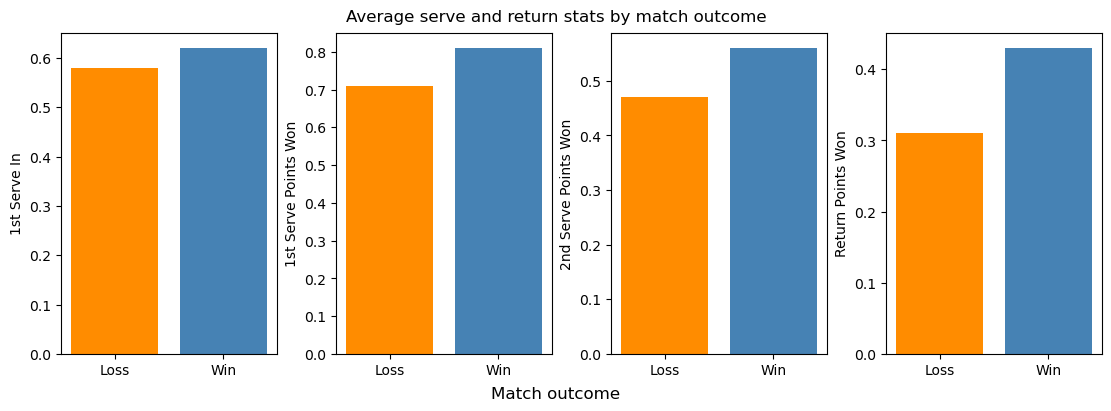

In [29]:
#Create a grouped bar chart by match outcome (win/loss)
fig, axs = plt.subplots(ncols = 4, figsize = (11, 4), layout = 'constrained')

#Set colors for bars
colors = {'Win': 'steelblue', 'Loss': 'darkorange'}

data_columns = ['pct_1stIn_avg', 'pct_1stWon_avg', 'pct_2ndWon_avg', 'rp_pct_avg']
labels = ['1st Serve In', '1st Serve Points Won', 
          '2nd Serve Points Won', 'Return Points Won']

for i, (col, label) in enumerate(zip(data_columns, labels)):
    axs[i].bar(avg_stats['outcome'], avg_stats[col],
               color = [colors[x] for x in avg_stats['outcome']])
    axs[i].tick_params(axis = 'x')
    axs[i].set_ylabel(label)
    
fig.supxlabel('Match outcome')
fig.suptitle('Average serve and return stats by match outcome')
    
plt.show()

In [30]:
#Count outcomes by opponent rank category
number_of_matches = jd_stats.groupby(['rank_category'])['outcome'].value_counts().to_frame()
number_of_matches.rename(columns = {'rank_category': 'rank_category', 'outcome': 'outcome', \
                                    'outcome': 'number_of_matches'}, inplace = True)
number_of_matches

count
rank_category   outcome       
TOP 10          Loss        16
                Win          8
TOP 11-50       Win         51
                Loss        28
TOP 50 and more Win         47
                Loss        11

In [31]:
#Analyze serve stats by rank category and match outcome
rank_stats = jd_stats.groupby(['rank_category', 'outcome'])[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', \
                                               'total_serve_win_pct', 'rp_pct']].mean().round(2)
rank_stats

ace    df  pct_1stIn  pct_1stWon  pct_2ndWon  \
rank_category   outcome                                                  
TOP 10          Loss     6.62  3.62       0.57        0.65        0.46   
                Win      8.75  2.75       0.59        0.79        0.56   
TOP 11-50       Loss     7.50  3.36       0.59        0.73        0.48   
                Win      7.69  2.24       0.61        0.81        0.58   
TOP 50 and more Loss     9.55  4.45       0.58        0.74        0.45   
                Win      9.06  2.77       0.62        0.82        0.55   

                         total_serve_win_pct  rp_pct  
rank_category   outcome                               
TOP 10          Loss                    0.56    0.30  
                Win                     0.69    0.38  
TOP 11-50       Loss                    0.63    0.32  
                Win                     0.72    0.43  
TOP 50 and more Loss                    0.62    0.32  
                Win                     0.72    0.44

In [32]:
#Save the index as a column with a new name
rank_stats = rank_stats.reset_index(drop = False)
rank_stats

,rank_category,outcome,ace,df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct,rp_pct
0,TOP 10,Loss,6.62,3.62,0.57,0.65,0.46,0.56,0.30
1,TOP 10,Win,8.75,2.75,0.59,0.79,0.56,0.69,0.38
2,TOP 11-50,Loss,7.50,3.36,0.59,0.73,0.48,0.63,0.32
3,TOP 11-50,Win,7.69,2.24,0.61,0.81,0.58,0.72,0.43
4,TOP 50 and more,Loss,9.55,4.45,0.58,0.74,0.45,0.62,0.32
5,TOP 50 and more,Win,9.06,2.77,0.62,0.82,0.55,0.72,0.44


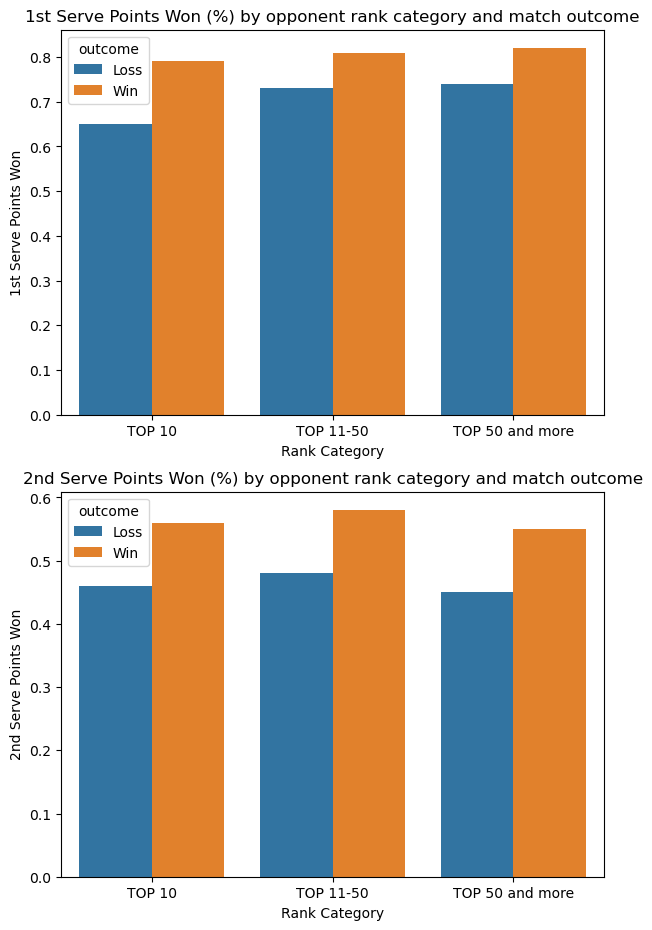

In [33]:
#Visualize the relationship between winners and unforced errors
fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (7, 11))

sns.barplot(data = rank_stats, x = "rank_category", y = "pct_1stWon", hue = 'outcome',  ax = ax[0])
ax[0].set_xlabel('Rank Category')
ax[0].set_ylabel('1st Serve Points Won')
ax[0].set_title('1st Serve Points Won (%) by opponent rank category and match outcome')

ax2 = sns.barplot(data = rank_stats, x = "rank_category", y = "pct_2ndWon", hue = 'outcome', ax = ax[1])
ax[1].set_xlabel('Rank Category')
ax[1].set_ylabel('2nd Serve Points Won')
ax[1].set_title('2nd Serve Points Won (%) by opponent rank category and match outcome')

plt.show()

**Conclusion**: 
- Across all matches and surfaces, Jack Draper averages 77.8% of points won on first serve and 53% of points on second serve.

- Jack Draper tends to lose more often against players ranked in the TOP 10. In his losses, his first serve percentage stands at 57%, compared to 59% in wins. He wins 65% of first serve points when he loses, versus 79% when he wins. Meanwhile, his second serve points won percentage is 46% in losses and 56% in victories.

### Compute correlations between serve stats and VIF

In [34]:
#Run correlation to see how serve stats and return points relate linearly
corr_matrix = jd_stats[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', 'rp_pct']].corr(method='pearson')
corr_matrix

,ace,df,pct_1stIn,pct_1stWon,pct_2ndWon,rp_pct
ace,1.000000,0.216852,0.127397,0.201256,-0.051289,-0.141537
df,0.216852,1.000000,-0.415941,-0.199820,-0.340029,-0.199400
pct_1stIn,0.127397,-0.415941,1.000000,0.067892,0.063645,0.036134
pct_1stWon,0.201256,-0.199820,0.067892,1.000000,0.308375,0.375403
pct_2ndWon,-0.051289,-0.340029,0.063645,0.308375,1.000000,0.229707
rp_pct,-0.141537,-0.199400,0.036134,0.375403,0.229707,1.000000


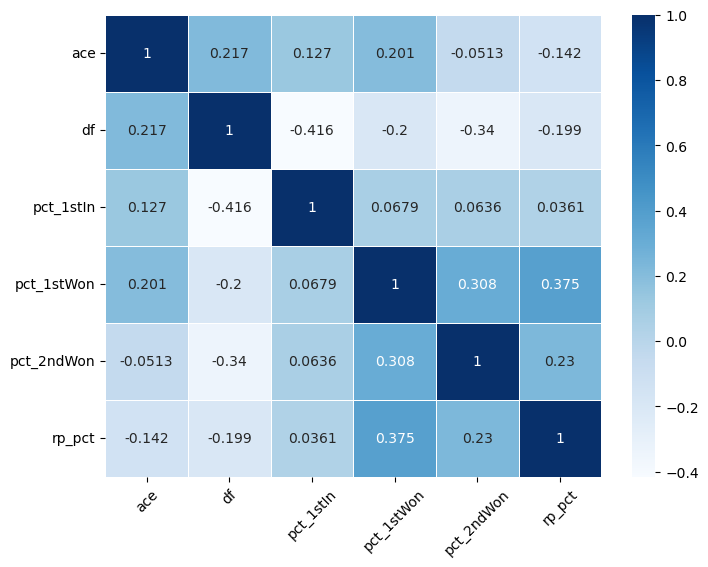

In [35]:
#Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, fmt='.3g', annot=True, linewidths=.5, cmap = 'Blues')
plt.xticks(rotation = 45)

plt.show()

**Conclusion**: Aces show a weak positive correlation with first serve percentage (0.127) and first serve points won (0.201), but almost no link with second serve points won (-0.051). Double faults are moderately negatively correlated with first serve percentage (-0.415) and second serve points won (-0.340). The strongest positive relationship is between first and second serve points won (0.308), suggesting that success on both serves tends to go together.

In [36]:
#Import libraries for calculating VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

#Isolate the dataset with independent variables
X1 = jd_stats[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', 'rp_pct', 'total_serve_win_pct']]

#Add a constant (intercept) column
X1_with_const = add_constant(X1)

#Calculate VIF for each variable
vif_1 = pd.DataFrame()
vif_1['Variable'] = X1_with_const.columns
vif_1['VIF'] = [variance_inflation_factor(X1_with_const.values, i) for i in range(X1_with_const.shape[1])]

vif_1

,Variable,VIF
0,const,425.203040
1,ace,1.290896
2,df,1.562280
3,pct_1stIn,4.313865
4,pct_1stWon,39.771702
5,pct_2ndWon,22.092549
6,rp_pct,1.302027
7,total_serve_win_pct,85.875824


Conclusion: The 'total_serve_win_pct' VIF is 85.87, indicating extremely high multicollinearity. This is possible because the 'total_serve_win_pct' variable is derived from the 'pct_1stIn', 'pct_1stWon', and 'pct_2ndWon' variables. Next step remove this variable and recalculate the VIF.

In [37]:
#Isolate the dataset with independent variables excluding 'total_serve_win_pct'
X2 = jd_stats[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', 'rp_pct']]

#Add a constant (intercept) column
X2_with_const = add_constant(X2)

#Calculate VIF for each variable
vif_2 = pd.DataFrame()
vif_2['Variable'] = X2_with_const.columns
vif_2['VIF'] = [variance_inflation_factor(X2_with_const.values, i) 
                   for i in range(X2_with_const.shape[1])]

vif_2

,Variable,VIF
0,const,211.224223
1,ace,1.256500
2,df,1.554612
3,pct_1stIn,1.304576
4,pct_1stWon,1.383431
5,pct_2ndWon,1.233058
6,rp_pct,1.251600


Conclusion: All VIF values show a moderate degree of multicollinearity. We will build a model using features without strong multicollinearity.

### Build Regression Model

In [38]:
#Import libraries for running logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [39]:
#Run logistic regression (the model with serve stats)
model_serve_stats = smf.glm('result ~ pct_1stWon + pct_2ndWon + ace + df', data = jd_stats, \
                                 family=sm.families.Binomial())
result_serve_stats = model_serve_stats.fit()
print(result_serve_stats.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 result   No. Observations:                  161
Model:                            GLM   Df Residuals:                      156
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -68.673
Date:                Tue, 01 Sep 2026   Deviance:                       137.35
Time:                        21:49:31   Pearson chi2:                     214.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.3502
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -14.3148      2.729     -5.245      0.0

In [40]:
#Fit the model to calculate probabilities of winning on each game
pred_probs_serve_stats = result_serve_stats.predict()
print(pred_probs_serve_stats[0:10])

#Based on the probabilites of winning, create a binary winning variable for 1 indicating 'Win', 0 indicating 'Lose'
pred_outcome_serve_stats = np.where(pred_probs_serve_stats > 0.5, 1, 0)
print(pred_outcome_serve_stats[0:10])

#Calculate an accuracy score of regression model
accuracy_serve_stats = (pred_outcome_serve_stats == jd_stats['result']).mean()
accuracy_serve_stats

[0.68805998 0.97227691 0.57332638 0.83849177 0.94765803 0.76869543
 0.40663943 0.99550701 0.81224815 0.7573093 ]
[1 1 1 1 1 1 0 1 1 1]


np.float64(0.8198757763975155)

In [41]:
#Show the main classification metrics (precision score, recall score, accuracy score)
print(classification_report(jd_stats['result'], pred_outcome_serve_stats, digits=3))

              precision    recall  f1-score   support

           0      0.771     0.673     0.718        55
           1      0.841     0.896     0.868       106

    accuracy                          0.820       161
   macro avg      0.806     0.784     0.793       161
weighted avg      0.817     0.820     0.817       161



In [42]:
#Run logistic regression (the model with serve stats and return points)
model_serve_stats_return = smf.glm('result ~ pct_1stWon + pct_2ndWon + ace + df + rp_pct', data = jd_stats, \
                family=sm.families.Binomial())
result_serve_stats_return = model_serve_stats_return.fit()
print(result_serve_stats_return.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 result   No. Observations:                  161
Model:                            GLM   Df Residuals:                      155
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -21.100
Date:                Tue, 01 Sep 2026   Deviance:                       42.201
Time:                        21:49:33   Pearson chi2:                     84.5
No. Iterations:                     9   Pseudo R-squ. (CS):             0.6402
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -58.1807     12.757     -4.561      0.0

In [43]:
#Fit the model to calculate probabilities of winning on each game
pred_probs_serve_stats_return = result_serve_stats_return.predict()
print(pred_probs_serve_stats_return[0:10])

#Based on the probabilites of winning, create a binary winning variable for 1 indicating 'Win', 0 indicating 'Lose'
pred_outcome_serve_stats_return = np.where(pred_probs_serve_stats_return > 0.5, 1, 0)
print(pred_outcome_serve_stats_return[0:10])

#Calculate an accuracy score of regression model
accuracy_serve_stats_return = (pred_outcome_serve_stats_return == jd_stats['result']).mean()
accuracy_serve_stats_return

[0.98869676 0.99131029 0.99984921 0.99649856 0.99994629 0.99999889
 0.84315424 1.         0.90494066 0.99994926]
[1 1 1 1 1 1 1 1 1 1]


np.float64(0.937888198757764)

In [44]:
#Show the main classification metrics (precision score, recall score, accuracy score)
print(classification_report(jd_stats['result'], pred_outcome_serve_stats_return, digits=3))

              precision    recall  f1-score   support

           0      0.895     0.927     0.911        55
           1      0.962     0.943     0.952       106

    accuracy                          0.938       161
   macro avg      0.928     0.935     0.932       161
weighted avg      0.939     0.938     0.938       161



In [45]:
#Compare R²
print(f"Only serve stats: R² = {result_serve_stats.pseudo_rsquared(kind='cs').round(2)}")
print(f"Serve stats with return: R² = {result_serve_stats_return.pseudo_rsquared(kind='cs').round(2)}")

Only serve stats: R² = 0.35
Serve stats with return: R² = 0.64


In [46]:
#Compare accuracy score of 2 models
print(f"Only serve stats: accuracy score = {accuracy_serve_stats.round(2)}")
print(f"Serve stats with return: accuracy score = {accuracy_serve_stats_return.round(2)}")

Only serve stats: accuracy score = 0.82
Serve stats with return: accuracy score = 0.94


In [47]:
#Determine how much an outcome variable changes when a specific predictor variable shifts by one unit, 
#while keeping all other variables constant
mfx = result_serve_stats_return.get_margeff(at='overall')
print(mfx.summary())

         GLM Marginal Effects        
Dep. Variable:                 result
Method:                          dydx
At:                           overall
                dy/dx    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
pct_1stWon     1.1789      0.215      5.477      0.000       0.757       1.601
pct_2ndWon     0.7520      0.147      5.103      0.000       0.463       1.041
ace            0.0068      0.004      1.797      0.072      -0.001       0.014
df            -0.0117      0.009     -1.279      0.201      -0.030       0.006
rp_pct         2.7270      0.240     11.362      0.000       2.257       3.197


**Conclusion**: 
- The extended logistic regression model confirms that first serve points won (p < 0.001), second serve points won (p < 0.001), and return points won (p < 0.001) are all statistically significant positive predictors of match outcomes for Jack Draper. In contrast, aces (p = 0.088) and double faults (p = 0.221) do not reach statistical significance, suggesting their individual impact is less reliable once other serve-related metrics are controlled for. The pseudo R-squared rises from 0.350 to 0.640 when return performance is added, indicating that these five metrics jointly account for a substantial share of the variation in match outcomes — with return points won contributing the largest gain in explanatory power. This confirms that Draper's wins and losses are best explained by consistent point conversion on both serve and return, rather than by aces or double faults in isolation.
- In practical terms: improving return points won by just 1 percentage point boosts Draper's win chance by 2.72 percentage points, improving first serve points won by 1 percentage point adds about 1.17 percentage points, and improving second serve points won by 1 percentage point adds about 0.75 percentage points. Aces and double faults barely matter for the final result once these percentages are accounted for.